In [ ]:
import pandas as pd
import io
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import string
import re

nltk.download('punkt')
nltk.download('stopwords')


file_path = '.../6-125.csv'  
df = pd.read_csv(file_path)


In [ ]:
df.to_csv('.../6-125.csv', index=False)


In [33]:
df['calculated_average'] = df['numbers'].apply(lambda x: sum(x) / len(x) if x else None)

df.head()

,issue,game,platform,review,number_1,number_2,number_3,number_4,number_5,number_6,number_7,number_8,year,month,average_score,numbers,calculated_average
0,6,Captain Cosmic,NES,Steve Harris 4 Ed Semrad 4 Martin Alessi 4 Jim...,4.0,4.0,4.0,4.0,NaN,NaN,NaN,NaN,1990,1,4.00,"[4.0, 4.0, 4.0, 4.0]",4.00
1,6,Dead Angle,Sega Master System,Steve Harris 6 Ed Semrad 5 Martin Alessi 6 Jim...,6.0,5.0,6.0,6.0,NaN,NaN,NaN,NaN,1990,1,5.75,"[6.0, 5.0, 6.0, 6.0]",5.75
2,6,Dragon Spirit,TurboGrafx-16,Steve Harris 7 Ed Semrad 6 Martin Alessi 7 Jim...,7.0,6.0,7.0,7.0,NaN,NaN,NaN,NaN,1990,1,6.75,"[7.0, 6.0, 7.0, 7.0]",6.75
3,6,DuckTales,NES,Steve Harris 8 Ed Semrad 9 Martin Alessi 8 Jim...,8.0,9.0,8.0,7.0,NaN,NaN,NaN,NaN,1990,1,8.00,"[8.0, 9.0, 8.0, 7.0]",8.00
4,6,Forgotten Worlds,Genesis,Steve Harris 8 Ed Semrad 8 Martin Alessi 8 Jim...,8.0,8.0,8.0,8.0,NaN,NaN,NaN,NaN,1990,1,8.00,"[8.0, 8.0, 8.0, 8.0]",8.00


In [28]:
df

,issue,game,platform,review,number_1,number_2,number_3,number_4,number_5,number_6,number_7,number_8,year,month,average_score
0,6,Captain Cosmic,NES,Steve Harris 4 Ed Semrad 4 Martin Alessi 4 Jim...,4.0,4.0,4.0,4.0,NaN,NaN,NaN,NaN,1990,1,4.000000
1,6,Dead Angle,Sega Master System,Steve Harris 6 Ed Semrad 5 Martin Alessi 6 Jim...,6.0,5.0,6.0,6.0,NaN,NaN,NaN,NaN,1990,1,5.750000
2,6,Dragon Spirit,TurboGrafx-16,Steve Harris 7 Ed Semrad 6 Martin Alessi 7 Jim...,7.0,6.0,7.0,7.0,NaN,NaN,NaN,NaN,1990,1,6.750000
3,6,DuckTales,NES,Steve Harris 8 Ed Semrad 9 Martin Alessi 8 Jim...,8.0,9.0,8.0,7.0,NaN,NaN,NaN,NaN,1990,1,8.000000
4,6,Forgotten Worlds,Genesis,Steve Harris 8 Ed Semrad 8 Martin Alessi 8 Jim...,8.0,8.0,8.0,8.0,NaN,NaN,NaN,NaN,1990,1,8.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2470,125,Vegas Games 2000,PlayStation,EGM Staff 5,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1999,12,5.000000
2471,125,WCW Mayhem,Nintendo 64,EGM Staff 5.5,5.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN,1999,12,5.000000
2472,125,WWF Wrestlemania 2000,Nintendo 64,Dan “Shoe” Hsu 8.5 Dean Hager 8 Chris “CJ” Joh...,8.0,5.0,8.0,8.0,5.0,8.0,NaN,NaN,1999,12,7.000000
2473,125,WWF Wrestlemania 2000,Game Boy Color,EGM Staff 6,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1999,12,6.000000


In [ ]:

# Define a function to extract all numbers (including decimals) from each review
def extract_numbers(text):
    return re.findall(r'\d+\.\d+|\d+', text)

# Extract numbers and create a new column in the DataFrame
df['numbers'] = df['review'].apply(extract_numbers)

# Convert the extracted numbers to floating-point values
df['numbers'] = df['numbers'].apply(lambda x: [float(num) for num in x])

# Find the maximum length among the extracted number lists
max_length = df['numbers'].apply(len).max()

# Create separate columns for each extracted number
for i in range(max_length):
    df[f'number_{i+1}'] = df['numbers'].apply(lambda x: x[i] if i < len(x) else None)

df.head()

,issue,game,platform,review,number_1,number_2,number_3,number_4,number_5,number_6,number_7,number_8,year,month,average_score,numbers
0,6,Captain Cosmic,NES,Steve Harris 4 Ed Semrad 4 Martin Alessi 4 Jim...,4.0,4.0,4.0,4.0,NaN,NaN,NaN,NaN,1990,1,4.00,"[4.0, 4.0, 4.0, 4.0]"
1,6,Dead Angle,Sega Master System,Steve Harris 6 Ed Semrad 5 Martin Alessi 6 Jim...,6.0,5.0,6.0,6.0,NaN,NaN,NaN,NaN,1990,1,5.75,"[6.0, 5.0, 6.0, 6.0]"
2,6,Dragon Spirit,TurboGrafx-16,Steve Harris 7 Ed Semrad 6 Martin Alessi 7 Jim...,7.0,6.0,7.0,7.0,NaN,NaN,NaN,NaN,1990,1,6.75,"[7.0, 6.0, 7.0, 7.0]"
3,6,DuckTales,NES,Steve Harris 8 Ed Semrad 9 Martin Alessi 8 Jim...,8.0,9.0,8.0,7.0,NaN,NaN,NaN,NaN,1990,1,8.00,"[8.0, 9.0, 8.0, 7.0]"
4,6,Forgotten Worlds,Genesis,Steve Harris 8 Ed Semrad 8 Martin Alessi 8 Jim...,8.0,8.0,8.0,8.0,NaN,NaN,NaN,NaN,1990,1,8.00,"[8.0, 8.0, 8.0, 8.0]"


In [ ]:
# Define a function to convert issue numbers into year and month
def issue_to_year_month(issue):
    base_year = 1990
    base_month = 1
    year = base_year + (issue - 6) // 12
    month = base_month + (issue - 6) % 12
    return year, month

# Apply the function to create new columns
df['year'], df['month'] = zip(*df['issue'].apply(issue_to_year_month))

C:\Users\70794\AppData\Local\Temp\ipykernel_41912\1159227537.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = plt.cm.get_cmap('tab20', len(platform_per_year.columns))  # Different colors


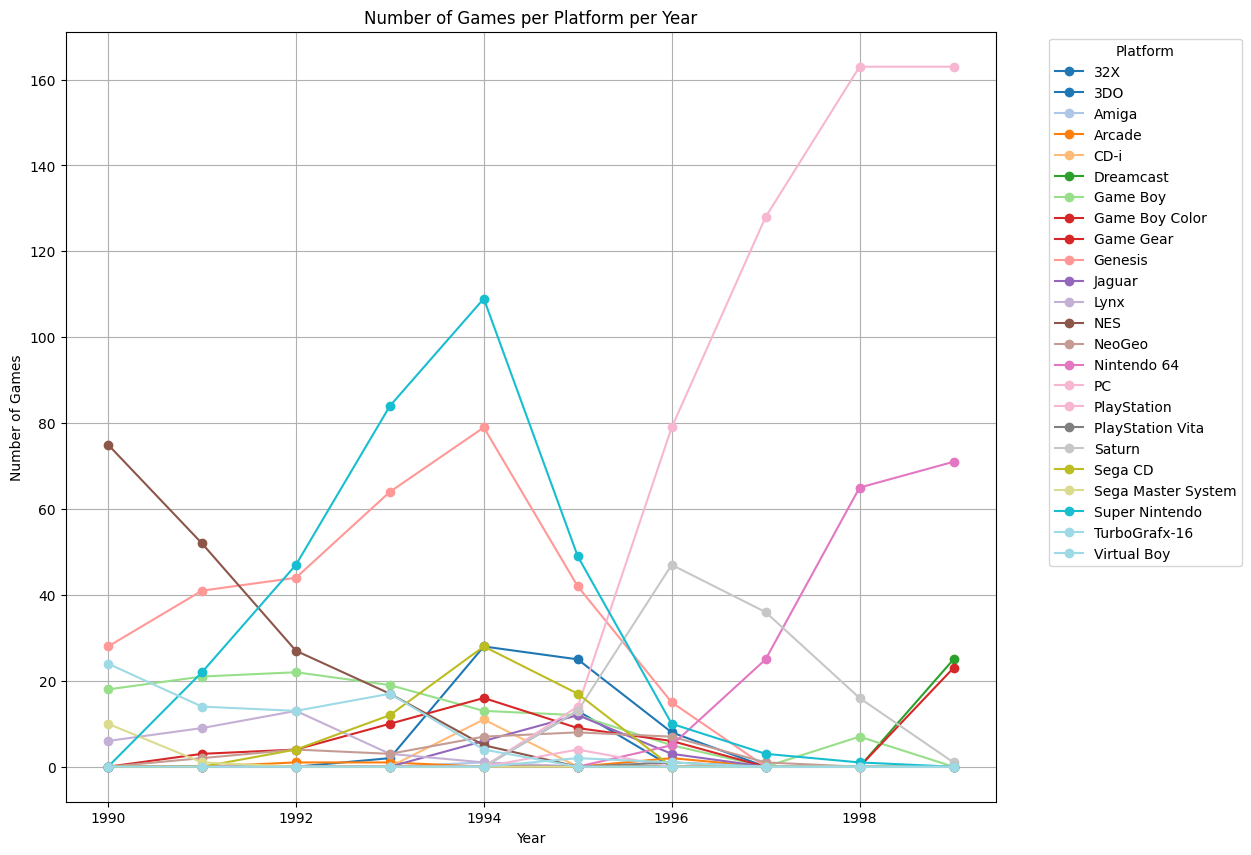

In [6]:
import matplotlib.pyplot as plt
# Remove duplicate entries based on game names, keeping only the first occurrence
data_first_occurrence = df.drop_duplicates(subset=['game'])

# Calculate the number of games for each platform per year
platform_per_year = data_first_occurrence.groupby(['year', 'platform']).size().unstack(fill_value=0)

# Plot the number of games for each platform per year
plt.figure(figsize=(12, 10))
colors = plt.cm.get_cmap('tab20', len(platform_per_year.columns))  # Different colors

for i, column in enumerate(platform_per_year.columns):
    plt.plot(platform_per_year.index, platform_per_year[column], 
             marker='o', label=column, linestyle='-', color=colors(i))

plt.title('Number of Games per Platform per Year')
plt.xlabel('Year')
plt.ylabel('Number of Games')
plt.legend(title='Platform', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
#plt.yticks(range(0, int(platform_per_year.values.max()) + 1, 1))  # Set y-axis ticks to integers
plt.show()

In [ ]:
# Calculate the average score for each row
df['average_score'] = df[['number_1', 'number_2', 'number_3', 'number_4', 'number_5', 'number_6', 'number_7', 'number_8']].mean(axis=1)

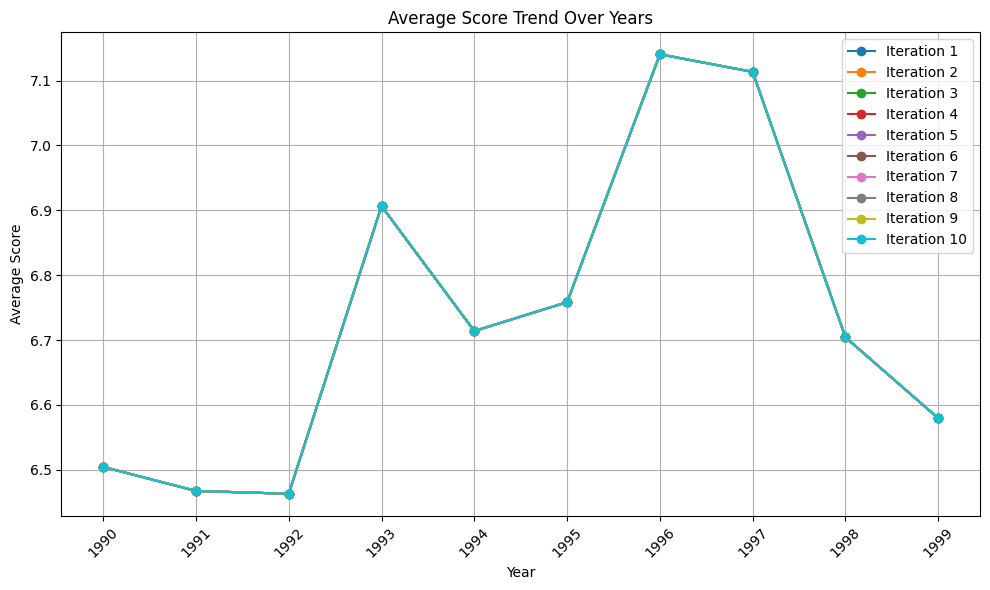

In [ ]:
# Initialize a DataFrame to store the yearly average scores across 10 iterations
yearly_averages_df = pd.DataFrame()

# Calculate the yearly average score for each of the 10 iterations
for i in range(10):
    yearly_average = df.groupby('year')['average_score'].mean()
    yearly_averages_df[f'Iteration {i+1}'] = yearly_average

# Plot the trend lines
plt.figure(figsize=(10, 6))

for column in yearly_averages_df.columns:
    plt.plot(yearly_averages_df.index, yearly_averages_df[column], marker='o', label=column)

plt.title('Average Score Trend Over Years')
plt.xlabel('Year')
plt.ylabel('Average Score')
plt.grid(True)
plt.xticks(yearly_averages_df.index, rotation=45)
plt.legend()
plt.tight_layout()

plt.show()

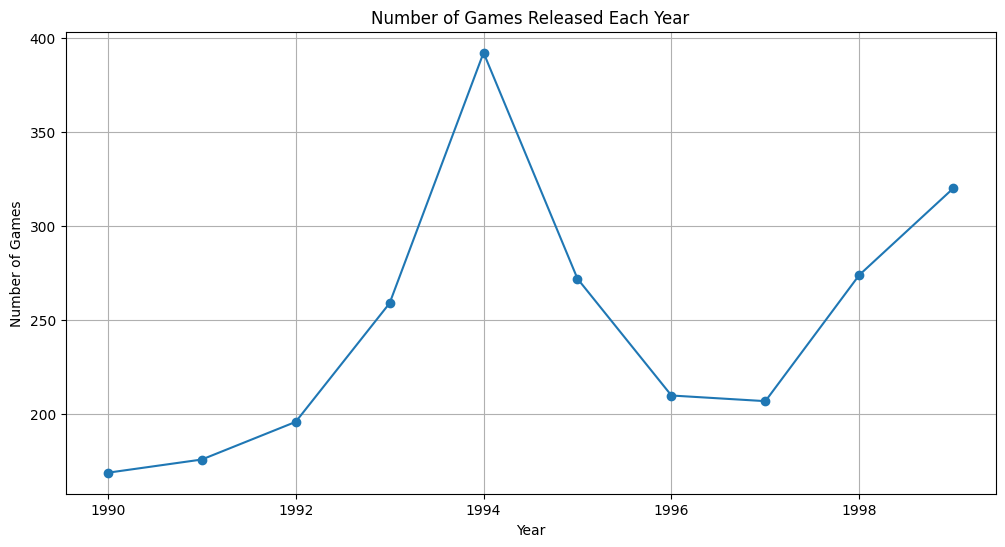

In [8]:

# Count the number of games released each year
games_per_year = df['year'].value_counts().sort_index()

# Plotting the number of games released each year
plt.figure(figsize=(12, 6))
plt.plot(games_per_year.index, games_per_year.values, marker='o')
plt.title('Number of Games Released Each Year')
plt.xlabel('Year')
plt.ylabel('Number of Games')
plt.grid(True)
plt.show()

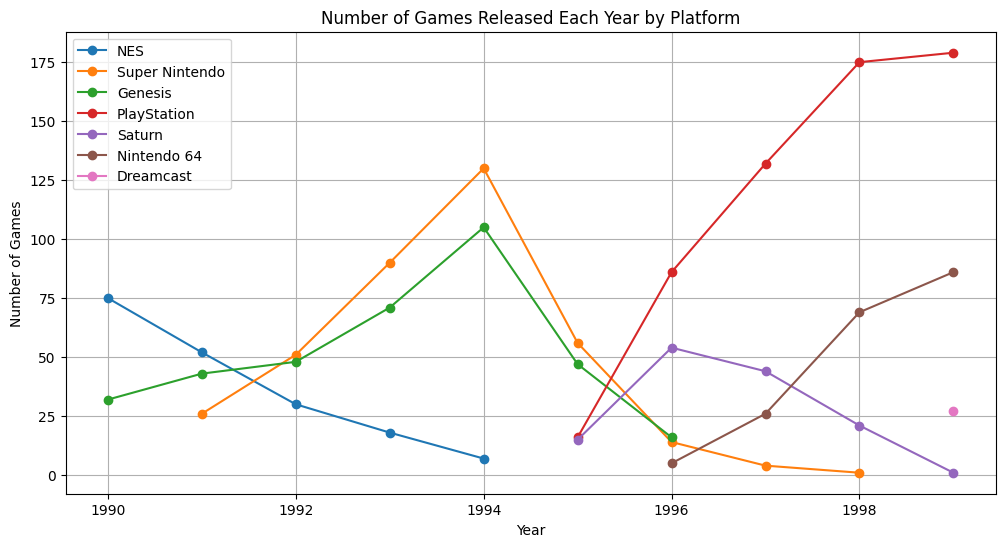

In [ ]:

# Define platforms to compare, including N64
platforms = ['NES', 'Super Nintendo', 'Genesis', 'PlayStation', 'Saturn', 'Nintendo 64', 'Dreamcast']
platform_names = {
    'NES': 'NES',
    'Super Nintendo': 'Super Nintendo',
    'Genesis': 'Genesis',
    'PlayStation': 'PlayStation',
    'Saturn': 'Saturn',
    'Nintendo 64': 'Nintendo 64',
    'Dreamcast': 'Dreamcast'
}

# Initialize a dictionary to store annual game release counts per platform
games_per_year = {}

# Calculate the number of games released each year for each platform
for platform in platforms:
    platform_games = df[df['platform'].str.lower() == platform.lower()]
    games_per_year[platform] = platform_games['year'].value_counts().sort_index()

# Plot the annual game release trends by platform
plt.figure(figsize=(12, 6))

for platform in platforms:
    plt.plot(games_per_year[platform].index, games_per_year[platform].values, marker='o', label=platform_names[platform])

plt.title('Number of Games Released Each Year by Platform')
plt.xlabel('Year')
plt.ylabel('Number of Games')
plt.legend()
plt.grid(True)
plt.show()

In [49]:
subset_df = df.iloc[1821:1823]
subset_df

,issue,game,platform,review,number_1,number_2,number_3,number_4,number_5,number_6,number_7,number_8,year,month,average_score,numbers
1821,99,Final Fantacy VII,PlayStation,Crispin Boyer 7.5 Shawn Smith 6.5 Dan “Shoe” H...,7.5,6.5,7.0,7.5,NaN,7.0,5.0,NaN,1997,10,7.125,"[7.5, 6.5, 7.0, 7.5]"
1822,99,Final Fantacy VII,PlayStation,Crispin Boyer 9.5 Shawn Smith 9.5 Dan “Shoe” H...,9.5,9.5,9.5,9.5,NaN,5.0,9.0,5.0,1997,10,9.500,"[9.5, 9.5, 9.5, 9.5]"


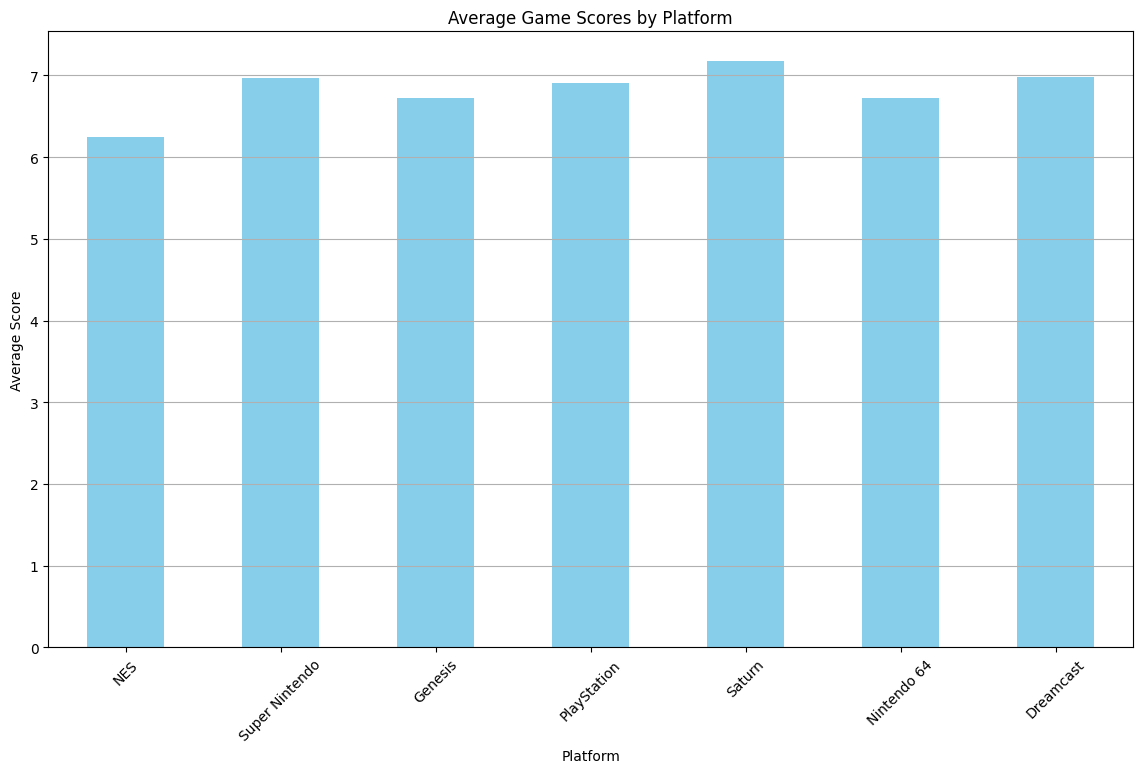

In [ ]:

# Define platforms to compare, including Nintendo 64 and Dreamcast
platforms = ['NES', 'Super Nintendo', 'Genesis', 'PlayStation', 'Saturn', 'Nintendo 64', 'Dreamcast']
platform_names = {
    'NES': 'NES',
    'Super Nintendo': 'Super Nintendo',
    'Genesis': 'Genesis',
    'PlayStation': 'PlayStation',
    'Saturn': 'Saturn',
    'Nintendo 64': 'Nintendo 64',
    'Dreamcast': 'Dreamcast'
}

# Filter data for the target platforms
filtered_df = df[df['platform'].str.lower().isin([p.lower() for p in platforms])]

# Calculate the overall average score for each platform
platform_avg_scores_overall = filtered_df.groupby('platform')['average_score'].mean().loc[platforms]

# Plot the average score bar chart by platform
plt.figure(figsize=(14, 8))
platform_avg_scores_overall.plot(kind='bar', color='skyblue')
plt.title('Average Game Scores by Platform')
plt.xlabel('Platform')
plt.ylabel('Average Score')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

In [ ]:
import seaborn as sns
# Create a boxplot to compare the distribution of ratings for different platforms
plt.figure(figsize=(14, 8))

# Generate boxplot for the ratings grouped by platform
sns.boxplot(x='platform', y='average_score', data=df, palette="muted")

plt.title('Rating Distribution per Platform')
plt.xlabel('Platform')
plt.ylabel('Rating')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

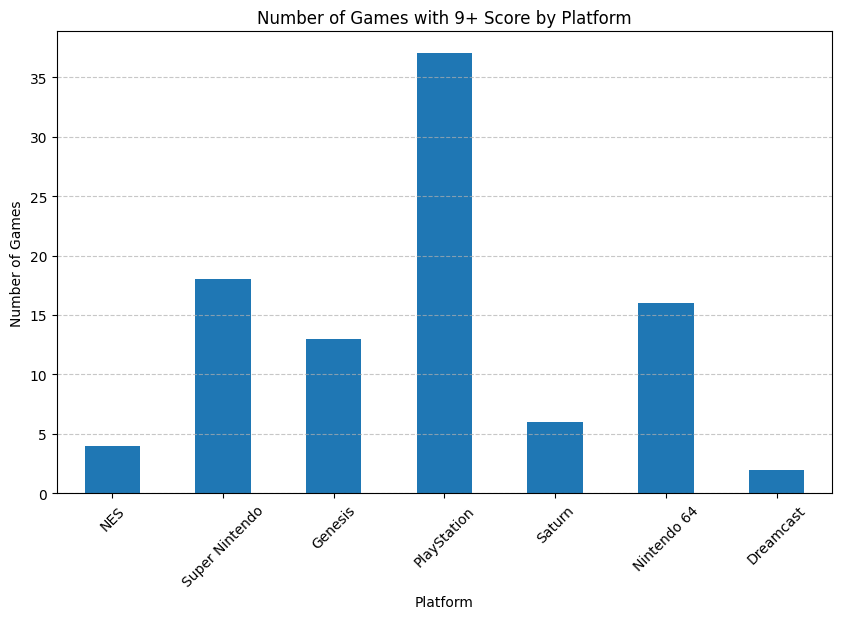

In [80]:
# Filter the data for the platforms of interest and games with an average score of 9 or higher
platforms_of_interest = ['NES', 'Super Nintendo', 'Genesis', 'PlayStation', 'Saturn', 'Nintendo 64', 'Dreamcast']
filtered_data = df[(df['platform'].isin(platforms_of_interest)) & (df['average_score'] >= 9)]

# Count the number of games with an average score of 9 or higher for each platform
platform_counts = filtered_data['platform'].value_counts().reindex(platforms_of_interest, fill_value=0)

# Plotting the data
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
platform_counts.plot(kind='bar')
plt.title('Number of Games with 9+ Score by Platform')
plt.xlabel('Platform')
plt.ylabel('Number of Games')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


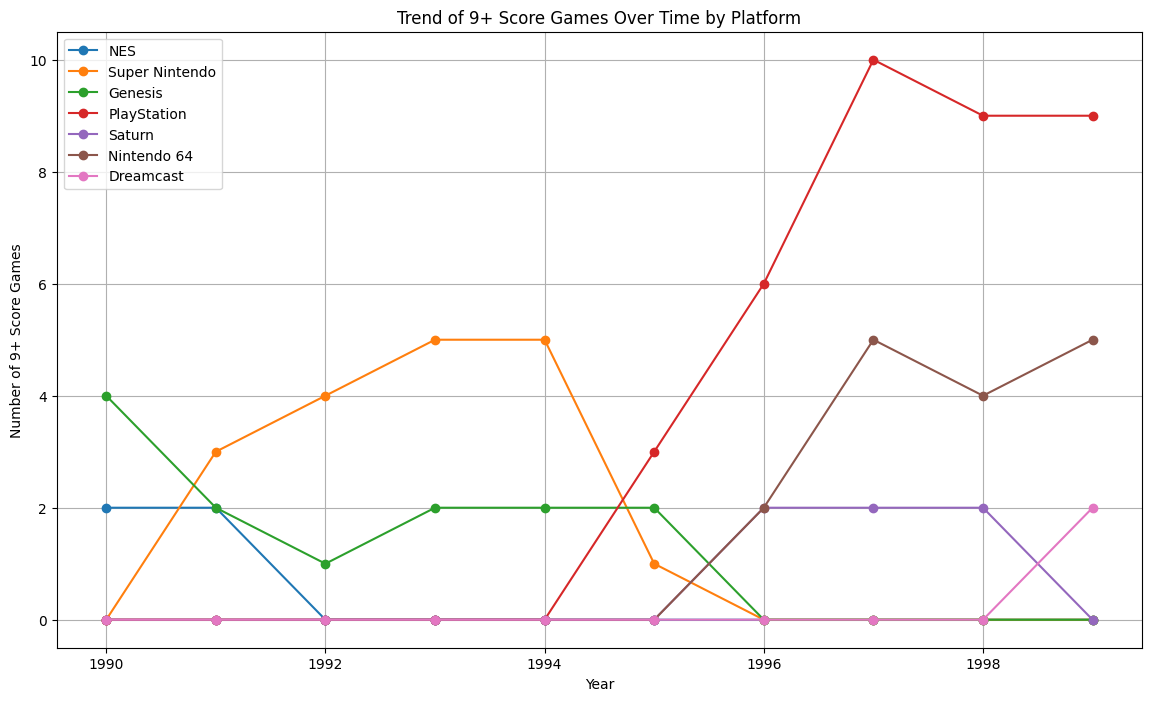

In [83]:
# Extract the year and count the number of 9+ score games for each platform per year
time_trend_data = filtered_data.groupby(['platform', 'year']).size().unstack(fill_value=0).transpose()

# Plotting the time trend data
plt.figure(figsize=(14, 8))

for platform in platforms_of_interest:
    if platform in time_trend_data.columns:
        plt.plot(time_trend_data.index, time_trend_data[platform], marker='o', label=platform)

plt.title('Trend of 9+ Score Games Over Time by Platform')
plt.xlabel('Year')
plt.ylabel('Number of 9+ Score Games')
plt.legend()
plt.grid(True)
plt.show()


In [77]:
filtered_data

,issue,game,platform,review,number_1,number_2,number_3,number_4,number_5,number_6,number_7,number_8,year,month,average_score,year_month
49,9,Super Mario Bros. 3,NES,Steve Harris 9 Ed Semrad 9 Martin Alessi 9 Jim...,9.0,9.0,9.0,9.0,NaN,NaN,NaN,NaN,1990,4,9.00,1990-04-01
128,15,Mega Man 3,NES,Steve Harris 9 Ed Semrad 9 Martin Alessi 9 Sus...,9.0,9.0,9.0,9.0,NaN,NaN,NaN,NaN,1990,10,9.00,1990-10-01
149,16,Strider,Genesis,Steve Harris 9 Ed Semrad 9 Martin Alessi 9 Sus...,9.0,9.0,9.0,9.0,NaN,NaN,NaN,NaN,1990,11,9.00,1990-11-01
150,16,Super Monaco GP,Genesis,Steve Harris 9 Ed Semrad 10 Martin Alessi 9 Su...,9.0,10.0,9.0,10.0,NaN,NaN,NaN,NaN,1990,11,9.50,1990-11-01
159,17,Castle of Illusion Starring Mickey Mouse,Genesis,Steve Harris 9 Ed Semrad 9 Martin Alessi 9 Sus...,9.0,9.0,9.0,9.0,NaN,NaN,NaN,NaN,1990,12,9.00,1990-12-01
164,17,John Madden Football (1990),Genesis,Steve Harris 9 Ed Semrad 9 Martin Alessi 9 Sus...,9.0,9.0,9.0,9.0,NaN,NaN,NaN,NaN,1990,12,9.00,1990-12-01
194,19,Quantum Fighter,NES,Steve Harris 9 Ed Semrad 9 Martin Alessi 9 Sus...,9.0,9.0,9.0,9.0,NaN,NaN,NaN,NaN,1991,2,9.00,1991-02-01
241,23,Battletoads,NES,Steve Harris 9 Ed Semrad 9 Martin Alessi 9 Sus...,9.0,9.0,9.0,9.0,NaN,NaN,NaN,NaN,1991,6,9.00,1991-06-01
264,24,Sonic the Hedgehog,Genesis,Steve Harris 9 Ed Semrad 9 Martin Alessi 9 Sus...,9.0,9.0,9.0,9.0,NaN,NaN,NaN,NaN,1991,7,9.00,1991-07-01
287,25,Streets of Rage,Genesis,Steve Harris 9 Ed Semrad 9 Martin Alessi 9 Sus...,9.0,9.0,9.0,9.0,NaN,NaN,NaN,NaN,1991,8,9.00,1991-08-01


In [ ]:
# Sort high-rated games chronologically by year
high_rating_games_sorted = high_rating_games.sort_values(by='year').reset_index(drop=True)

# Display the sorted list of high-rated games

#high_rating_games_sorted.head(60)
len(high_rating_games_sorted)

55

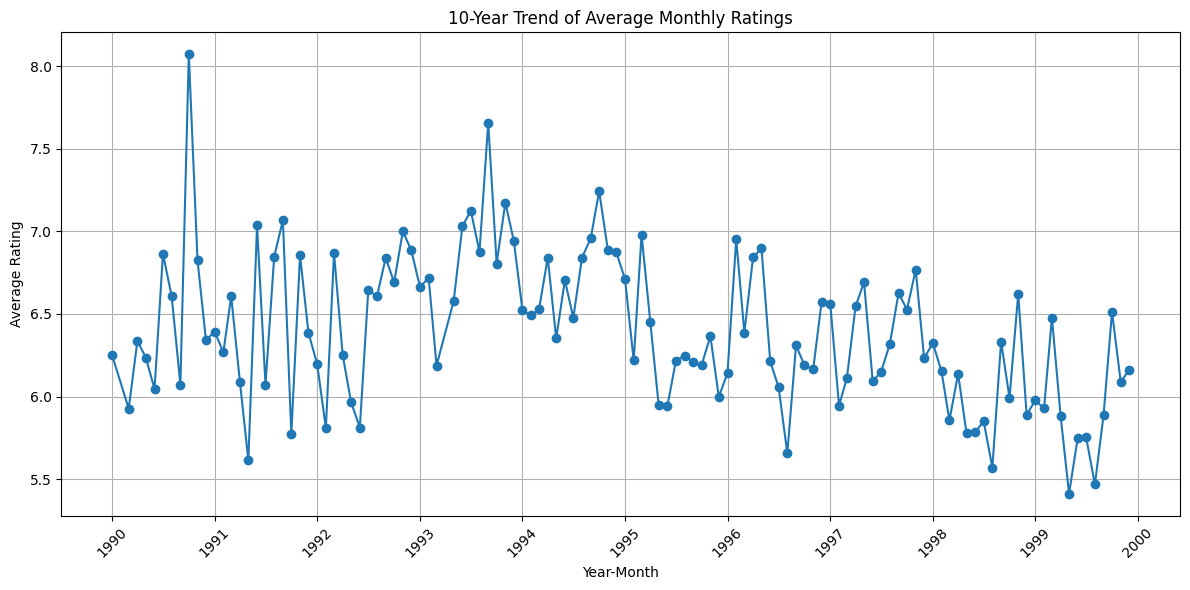

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
data = pd.read_csv(file_path)

# Generate 'year_month' column
data['year_month'] = data['year'].astype(str) + '-' + data['month'].astype(str).str.zfill(2)

# Convert 'year_month' to datetime format
data['year_month'] = pd.to_datetime(data['year_month'])

# Group by 'year_month' and calculate the average rating for each month
monthly_avg_rating = data.groupby('year_month')['average_score'].mean()

# Plot the trend of average ratings over the 10-year period
plt.figure(figsize=(12, 6))
plt.plot(monthly_avg_rating.index, monthly_avg_rating.values, marker='o', linestyle='-')
plt.title('10-Year Trend of Average Monthly Ratings')
plt.xlabel('Year-Month')
plt.ylabel('Average Rating')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

# Show the plot
plt.show()


In [70]:
# Filter the dataframe to include only games with an average score of 9 or above
high_score_games = df[df['average_score'] >= 9][['game', 'year', 'month', 'average_score']]

# Sort the dataframe by year and month
high_score_games_sorted = high_score_games.sort_values(by=['year', 'month'])

# Display the dataframe to the user

len(high_score_games_sorted)


107

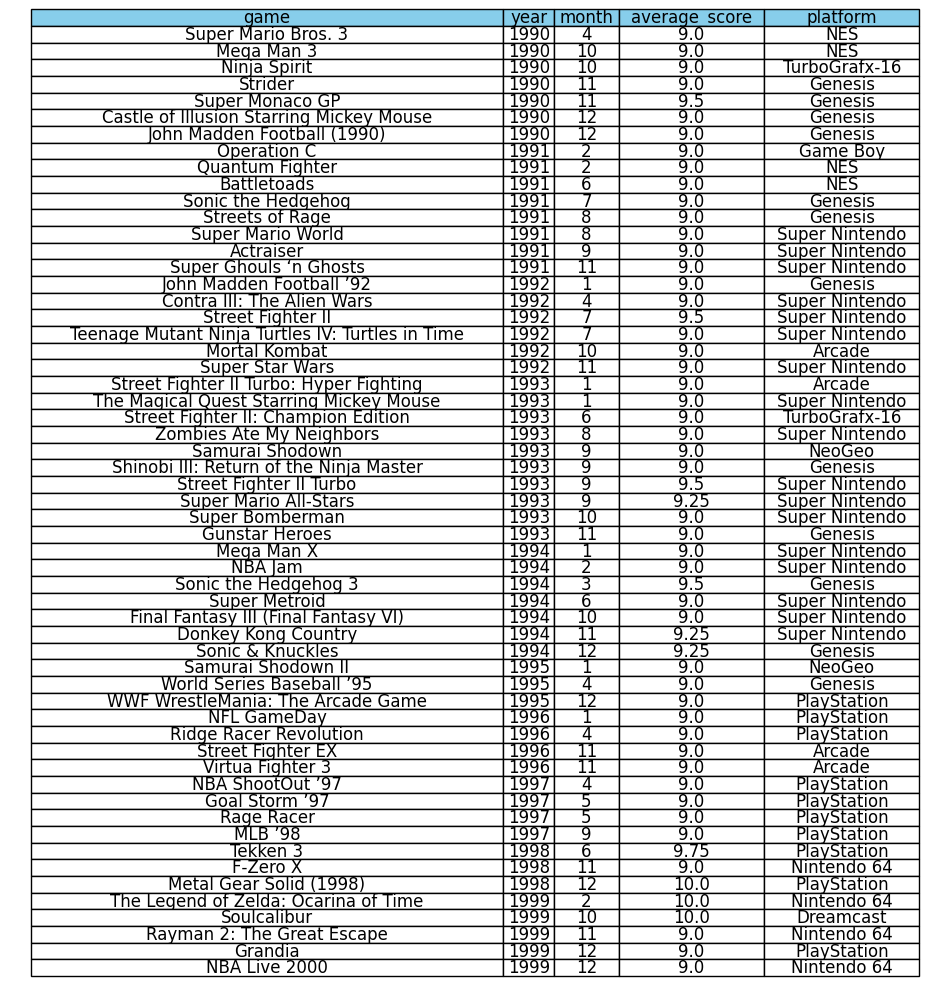

In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.table as tbl

# Filter the dataframe to include only games with an average score of 9 or above
high_score_games = df[df['average_score'] >= 9][['game', 'year', 'month', 'average_score','platform']]

# Sort the dataframe by year and month
# high_score_games_sorted = high_score_games.sort_values(by=['year', 'month'])
high_score_games_sorted = high_score_games.sort_values(by=['year', 'month'])
# Plotting the table
fig, ax = plt.subplots(figsize=(12, 10))
ax.axis('tight')
ax.axis('off')
table = tbl.table(ax, cellText=high_score_games_sorted.values,
                  colLabels=high_score_games_sorted.columns,
                  cellLoc='center', loc='center', colColours=['skyblue']*len(high_score_games_sorted.columns))

table.auto_set_font_size(False)
table.set_fontsize(12)
table.auto_set_column_width(col=list(range(len(high_score_games_sorted.columns))))

plt.show()

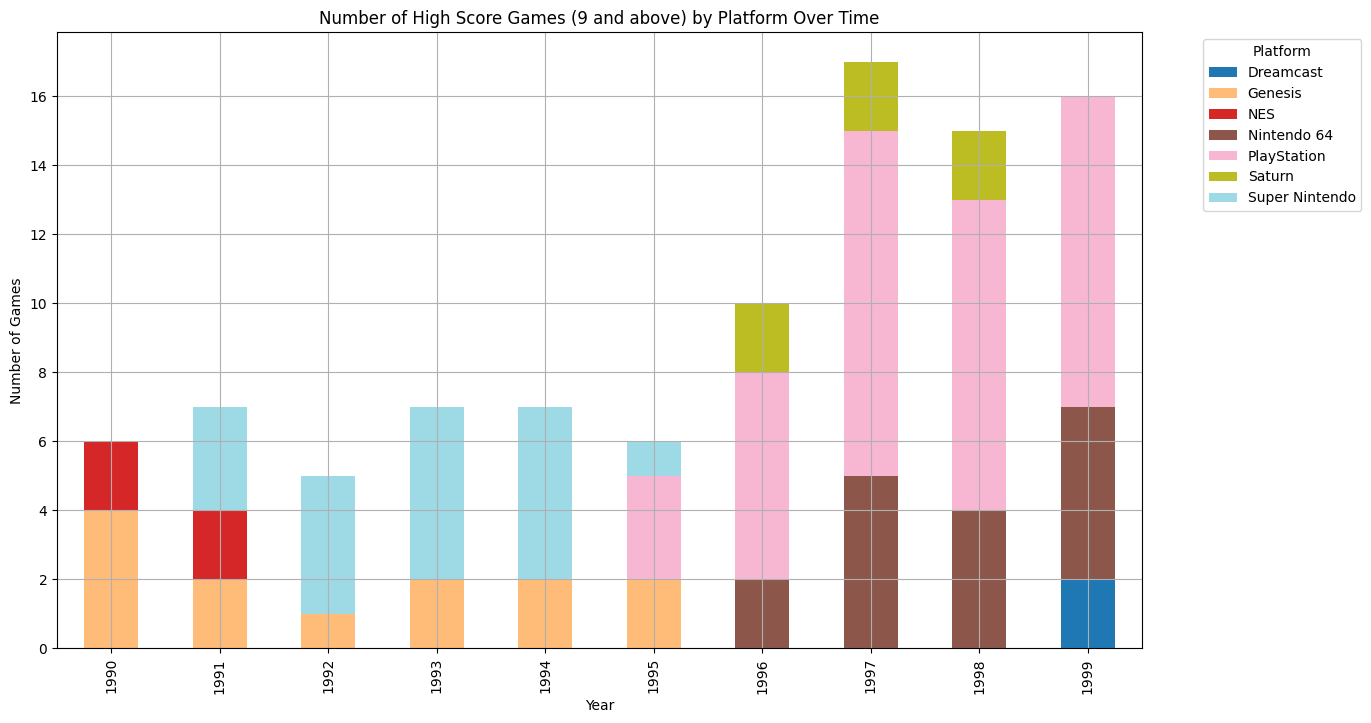

In [87]:
# Group by the simplified date (year) and platform, then count the number of games
high_score_games_count = filtered_data.groupby(['year', 'platform']).size().unstack(fill_value=0)

# Plotting the number of high score games over time for each platform as a stacked bar chart
high_score_games_count.plot(kind='bar', stacked=True, figsize=(14, 8), colormap='tab20')

plt.title('Number of High Score Games (9 and above) by Platform Over Time')
plt.xlabel('Year')
plt.ylabel('Number of Games')
plt.legend(title='Platform', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()


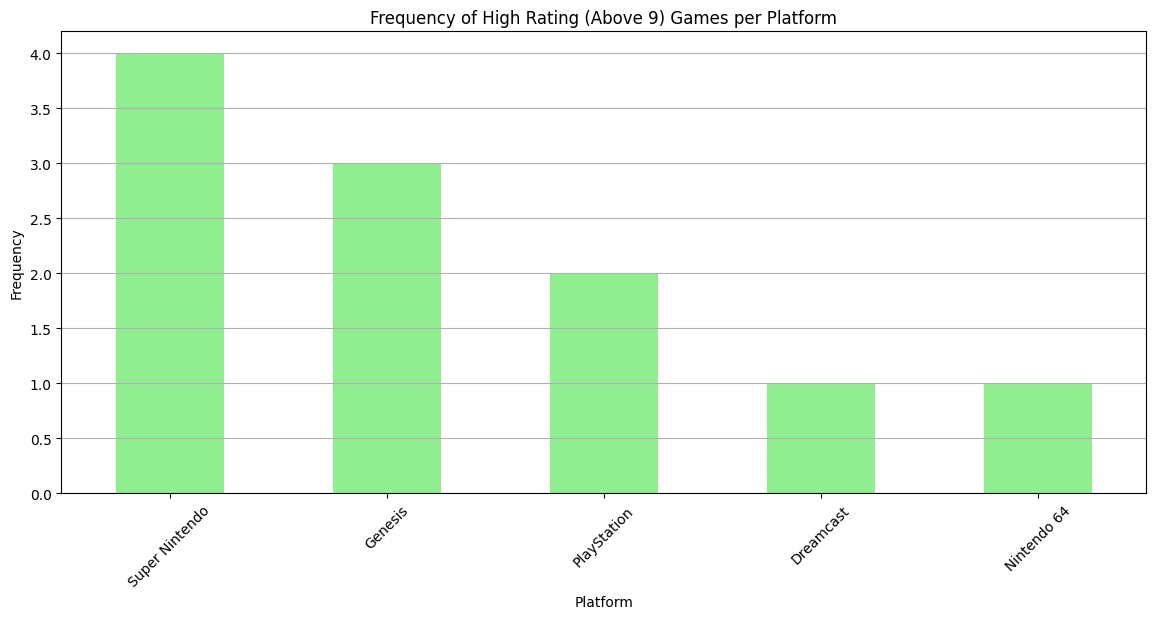

In [ ]:
# Remove duplicate game entries by calculating the average rating for each game
df_unique_avg = df.groupby(['game', 'platform', 'year']).agg({'average_score': 'mean'}).reset_index()

# 1. Frequency analysis of popular game platforms/types
# Filter high-rated games (scores strictly greater than 9)
high_rating_games = df_unique_avg[df_unique_avg['average_score'] > 9]
high_rating_game_type_counts = high_rating_games['platform'].value_counts()
high_rating_game_type_counts


# 2. Platform distribution of high-rated games
# Count the number of high-rated games across different platforms
high_rating_platform_counts = high_rating_games['platform'].value_counts()

# Plot the platform distribution bar chart for high-rated games
plt.figure(figsize=(14, 6))
high_rating_platform_counts.plot(kind='bar', color='lightgreen')
plt.title('Frequency of High Rating (Above 9) Games per Platform')
plt.xlabel('Platform')
plt.ylabel('Frequency')
plt.grid(axis='y')
plt.xticks(rotation=45)
plt.show()

In [67]:

# Remove duplicate game entries by calculating the average rating for each game
df_unique_avg = df.groupby(['game', 'platform', 'year']).agg({'average_score': 'mean'}).reset_index()

# Find the highest rated game for each year
highest_rated_games_per_year = df_unique_avg.loc[df_unique_avg.groupby('year')['average_score'].idxmax()]

# Select relevant columns to display
highest_rated_games_per_year = highest_rated_games_per_year[['year', 'game', 'platform', 'average_score']]

print(highest_rated_games_per_year)

      year                     game        platform  average_score
1936  1990          Super Monaco GP         Genesis            9.5
173   1991              Battletoads             NES            9.0
1884  1992        Street Fighter II  Super Nintendo            9.5
1885  1993  Street Fighter II Turbo  Super Nintendo            9.5
1781  1994     Sonic the Hedgehog 3         Genesis            9.5
1668  1995       Samurai Shodown II          NeoGeo            9.0
1276  1996              NFL GameDay     PlayStation            9.0
756   1997           Goal Storm ’97     PlayStation            9.0
1117  1998  Metal Gear Solid (1998)     PlayStation           10.0
1787  1999              Soulcalibur       Dreamcast           10.0


In [88]:
data = df

In [ ]:
# Filter games on specified platforms containing "Mario" with an average score >= 9
platforms_mario = ['NES', 'Super Nintendo', 'Nintendo 64']
mario_high_score_games = data[(data['platform'].isin(platforms_mario)) & 
                              (data['game'].str.contains('Mario', case=False, na=False)) & 
                              (data['average_score'] >= 9)]

# Select relevant columns
mario_high_score_games_filtered = mario_high_score_games[['game', 'platform', 'average_score', 'year']]

# Display the results
print(mario_high_score_games_filtered)

                       game        platform  average_score  year
49      Super Mario Bros. 3             NES           9.00  1990
289       Super Mario World  Super Nintendo           9.00  1991
675   Super Mario All-Stars  Super Nintendo           9.25  1993
1602         Super Mario 64     Nintendo 64           9.50  1996
1727          Mario Kart 64     Nintendo 64           9.25  1997


,game,platform,average_score,year
49,Super Mario Bros. 3,NES,9.00,1990
289,Super Mario World,Super Nintendo,9.00,1991
675,Super Mario All-Stars,Super Nintendo,9.25,1993
1602,Super Mario 64,Nintendo 64,9.50,1996
1727,Mario Kart 64,Nintendo 64,9.25,1997
